First five rows:
            Page_Views
Date                  
2025-01-01  512.417854
2025-01-02  561.089911
2025-01-03  598.186446
2025-01-04  578.786446
2025-01-05  467.435467


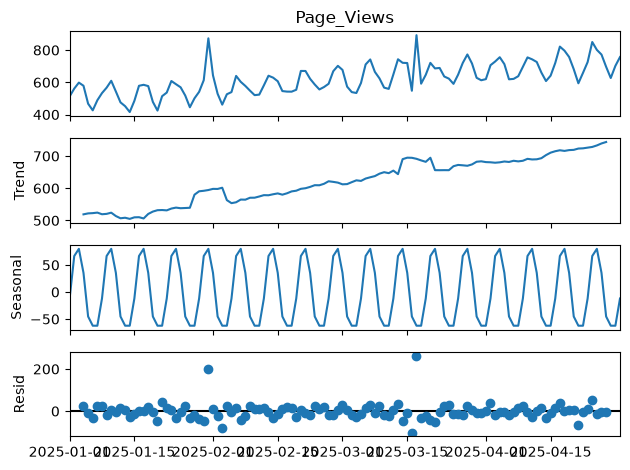

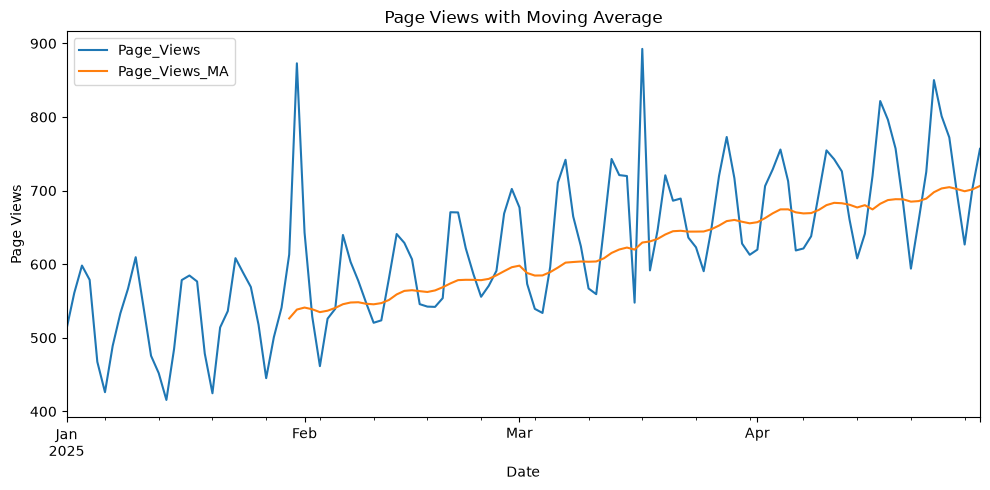

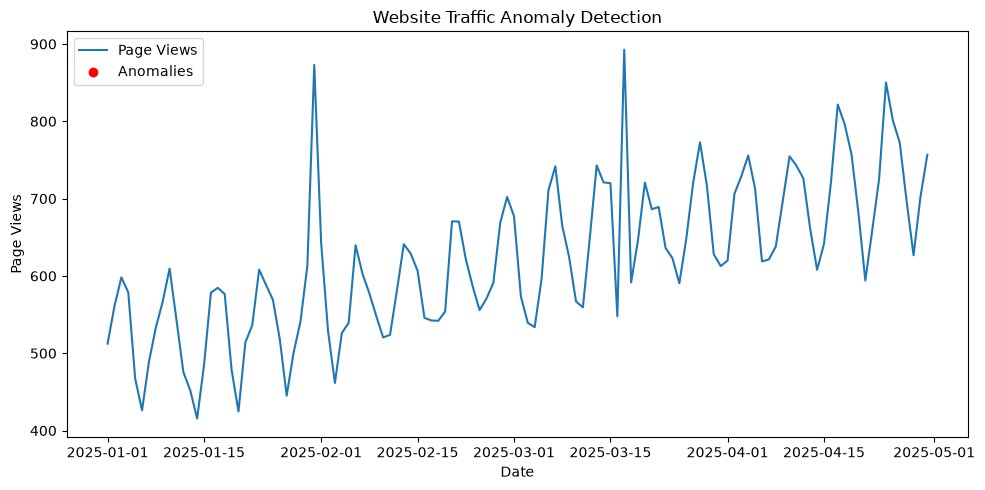

Number of anomalies detected: 0

Anomalies:
Empty DataFrame
Columns: [Page_Views, Page_Views_Z]
Index: []

Analysis completed successfully!


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
import numpy as np

# Step 1: Create sample website traffic data
dates = pd.date_range(start='2025-01-01', periods=120, freq='D')
np.random.seed(42)

page_views = (
    500
    + np.arange(120) * 2
    + 80 * np.sin(2 * np.pi * np.arange(120) / 7)
    + np.random.normal(0, 25, 120)
)

# Add a few unusual traffic spikes
page_views[30] += 250
page_views[75] += 300

data = pd.DataFrame({
    'Date': dates,
    'Page_Views': page_views
})

# Step 2: Save and load the CSV file
data.to_csv('website_traffic.csv', index=False)

data = pd.read_csv(
    'website_traffic.csv',
    parse_dates=['Date'],
    index_col='Date'
)

print("First five rows:")
print(data.head())

# Step 3: Time Series Decomposition
decomposition = seasonal_decompose(
    data['Page_Views'],
    model='additive',
    period=7
)

decomposition.plot()
plt.tight_layout()
plt.show()

# Step 4: Moving Average
data['Page_Views_MA'] = data['Page_Views'].rolling(
    window=30
).mean()

data[['Page_Views', 'Page_Views_MA']].plot(figsize=(10, 5))
plt.title('Page Views with Moving Average')
plt.xlabel('Date')
plt.ylabel('Page Views')
plt.tight_layout()
plt.show()

# Step 5: Anomaly Detection using Z-score
data['Page_Views_Z'] = (
    (data['Page_Views'] - data['Page_Views'].mean())
    / data['Page_Views'].std()
)

anomalies = data[data['Page_Views_Z'].abs() > 3]

# Step 6: Plot detected anomalies
plt.figure(figsize=(10, 5))
plt.plot(data.index, data['Page_Views'], label='Page Views')

plt.scatter(
    anomalies.index,
    anomalies['Page_Views'],
    color='red',
    label='Anomalies'
)

plt.title('Website Traffic Anomaly Detection')
plt.xlabel('Date')
plt.ylabel('Page Views')
plt.legend()
plt.tight_layout()
plt.show()

print("Number of anomalies detected:", len(anomalies))
print("\nAnomalies:")
print(anomalies[['Page_Views', 'Page_Views_Z']])

print("\nAnalysis completed successfully!")
